<a href="https://colab.research.google.com/github/Lathigasrijagannathan/artifical-intelligence/blob/main/Another_copy_of_Untitled5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_csv("TSLA.CSV")
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'TSLA.CSV'

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving weather_forecast_data.csv to weather_forecast_data (1).csv


In [ ]:
import pandas as pd
df = pd.read_csv("isha.csv")
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'isha.csv'

In [ ]:
import os
print(os.listdir())

['.config', 'weather_forecast_data.csv', 'weather_forecast_data (1).csv', 'sample_data']


In [ ]:
import pandas as pd
df = pd.read_csv("weather_forecast_data (1).csv")
print(df.head())

   Temperature   Humidity  Wind_Speed  Cloud_Cover     Pressure     Rain
0    23.720338  89.592641    7.335604    50.501694  1032.378759     rain
1    27.879734  46.489704    5.952484     4.990053   992.614190  no rain
2    25.069084  83.072843    1.371992    14.855784  1007.231620  no rain
3    23.622080  74.367758    7.050551    67.255282   982.632013     rain
4    20.591370  96.858822    4.643921    47.676444   980.825142  no rain


In [ ]:
df.columns

Index(['Temperature', 'Humidity', 'Wind_Speed', 'Cloud_Cover', 'Pressure',
       'Rain'],
      dtype='object')

In [ ]:
rain = df[["Rain"]]
print(rain.head())

      Rain
0     rain
1  no rain
2  no rain
3     rain
4  no rain


In [ ]:
rain = rain.replace({"rain":1 , "no rain" :0})
print(rain.head())

   Rain
0     1
1     0
2     0
3     1
4     0


In [ ]:
X = []
y = []
for i in range(3,len(rain)):
  X.append(rain.iloc[i-3:i].values)
  y.append(rain.iloc[i])

In [ ]:
import numpy as np
X = np.array(X)
y = np.array(y)
print(X.shape)
print(y.shape)

(2497, 3, 1)
(2497, 1)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense
model = Sequential([LSTM(32,input_shape=(X.shape[1],X.shape[2])),
                    Dense(1,activation="sigmoid")])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="adam",
loss="binary_crossentropy",metrics=["accuracy"])

In [ ]:
history = model.fit(X,y,epochs=10,batch_size=32,class_weight={0: 1,1:7})

Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8746 - loss: 1.3201
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8742 - loss: 1.2169
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8742 - loss: 1.2158
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1650 - loss: 1.2147
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1562 - loss: 1.2147
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3801 - loss: 1.2144
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.4417 - loss: 1.2145
Epoch 8/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4501 - loss: 1.2143
Epoch 9/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5346 - loss: 1.2143
Epoch 10/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3817 - loss: 1.2145


In [ ]:
prediction= model.predict(X)
predicted_class = (prediction > 0.5).astype(int)
print(predicted_class[:20])

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
[[0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]]


In [ ]:
print(prediction[:10])

[[0.09533066]
 [0.10440597]
 [0.10223601]
 [0.09533066]
 [0.11507256]
 [0.11507256]
 [0.11507256]
 [0.10440597]
 [0.10223601]
 [0.08695885]]


In [ ]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y,predicted_class)
print("accuracy:",accuracy)

accuracy: 0.381657989587505


In [ ]:
split = int(len(X)*0.8)
X_train = X[:split]
X_test = X[split]
y_train = y[:split]
y_test = y[split:]
print(X_train.shape)
print(X_test.shape)

(1997, 3, 1)
(3, 1)


In [ ]:
history = model.fit(X,y,epochs=10,batch_size=32)

Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8506 - loss: 0.5686
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8746 - loss: 0.3833
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8746 - loss: 0.3796
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8746 - loss: 0.3788
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8746 - loss: 0.3782
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8746 - loss: 0.3783
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8746 - loss: 0.3776
Epoch 8/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8746 - loss: 0.3777
Epoch 9/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8746 - loss: 0.3785
Epoch 10/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8746 - loss: 0.3788


In [ ]:
print(X_test.shape)
print(X_test.dtype)

(3, 1)
int64


In [ ]:
print(X.shape)
print(X_test.shape)

(2497, 3, 1)
(3, 1)


In [ ]:
split = int(len(X)*0.8)
X_train = X[:split]
X_test = X[split]
y_train = y[:split]
y_test = y[split:]

In [ ]:
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)

X_train: (1997, 3, 1)
X_test: (3, 1)


In [ ]:
print(type(X))

<class 'numpy.ndarray'>


In [ ]:
print(X.shape)
print(len(X))

(2497, 3, 1)
2497


In [ ]:
split = int(len(X) * 0.8)
X_train = X[:split]
X_test = X[split]
print(X_train.shape)
print(X_test.shape)

(1997, 3, 1)
(3, 1)


In [ ]:
test_data = X[1997:]
print(test_data.shape)

(500, 3, 1)


In [ ]:
test_prediction = model.predict(test_data)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


In [ ]:
print(test_prediction[:10])

[[0.12654124]
 [0.12654124]
 [0.11732773]
 [0.11452235]
 [0.10184626]
 [0.12654124]
 [0.12654124]
 [0.12654124]
 [0.12654124]
 [0.12654124]]


In [ ]:
test_class= (test_prediction > 0.5).astype(int)
print(test_class[:10])

[[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]]


In [ ]:
print(y_test[:20])

[[0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]]


In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,test_class)
print(cm)

[[438   0]
 [ 62   0]]


In [ ]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test,test_class)
print("test accuracy",accuracy)

test accuracy 0.876


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test,test_class))

              precision    recall  f1-score   support

           0       0.88      1.00      0.93       438
           1       0.00      0.00      0.00        62

    accuracy                           0.88       500
   macro avg       0.44      0.50      0.47       500
weighted avg       0.77      0.88      0.82       500



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


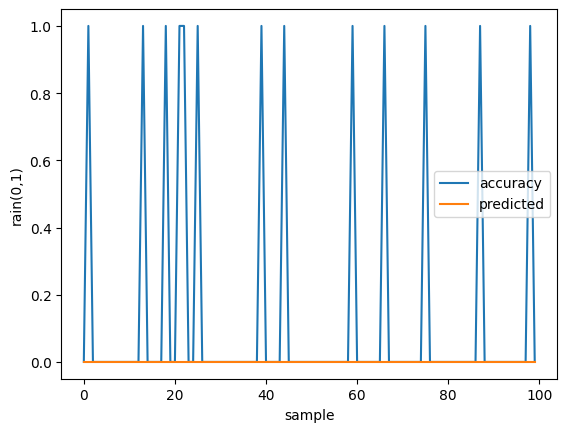

In [ ]:
import matplotlib.pyplot as plt
plt.plot(y_test[:100],label="accuracy")
plt.plot(test_class[:100],label="predicted")
plt.xlabel("sample")
plt.ylabel("rain(0,1)")
plt.legend()
plt.show()